In [1]:
# Core RAG Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install langchain-community
!pip install langchain-text-splitters
!pip install langchain
!pip install faiss-cpu
!pip install tiktoken
!pip install openai
!pip install grandalf




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.6/123.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.1/565.1 kB 15.8 MB/s eta 0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.4.9
    Uninstalling langchain-core-1.4.9:
      Successfully uninstalled langchain-core-1.4.9
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.2 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-

In [16]:



# Import all depedencies

from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_community.vectorstores import FAISS
from langchain_core.tools import create_retriever_tool
from langchain.agents import create_agent
from langchain_classic.agents import create_tool_calling_agent, AgentExecutor
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage

from langgraph.graph import START, END, MessagesState
from langgraph.graph import StateGraph
from langgraph.prebuilt import ToolNode
from IPython.display import display,Image


# Import the Python SDK for Colab secrets
from google.colab import userdata



In [4]:
import os

# Fetch the API key from Colab secrets
openai_api_key = userdata.get('OPENAI_APIKEY')

# Set up Environmental Variables
os.environ["OPENAI_API_KEY"] = openai_api_key

In [5]:
# ==========================================
# Step 1: Prepare Knowledge Base (Documents)
# ==========================================
# For demonstration, creating a dummy document

sample_text = """
ACME Corp Remote Work Policy (2026):
1. Employees may work remotely up to 3 days per week with manager approval.
2. A annual stipend of $500 is provided for home office equipment setup.
3. Core working hours are 10:00 AM to 4:00 PM EST.
4. Internet reimbursement covers up to $70/month with valid receipts.
"""

with open("company_policy.txt", "w") as f:
    f.write(sample_text)

# Load and split documents into chunks
loader = TextLoader("company_policy.txt")
documents = loader.load()

In [6]:
# Load and split documents into chunks
loader = TextLoader("company_policy.txt")
documents = loader.load()

text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
docs = text_splitter.split_documents(documents)

In [7]:
# Embed and store in Vector Database (FAISS)
embeddings = OpenAIEmbeddings()
vectorstore = FAISS.from_documents(docs, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

In [8]:
# ==========================================
# Step 2: Create the RAG Retriever Tool
# ==========================================
# This wraps the retriever into a tool that the Agent can call on demand.
retriever_tool = create_retriever_tool(
    retriever,
    name="company_policy_search",
    description="Searches and retrieves relevant policy information regarding ACME Corp."
)


In [9]:
# ==========================================
# Step 3: Initialize LLM and Prompt
# ==========================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an intelligent internal HR assistant. "
               "Use the tools provided to look up official policy facts before answering. "
               "If information is not present in the documents, state that clearly."),
    MessagesPlaceholder(variable_name="chat_history", optional=True),
    ("human", "{input}"),
    MessagesPlaceholder(variable_name="agent_scratchpad"),
])

In [10]:
# ==========================================
# Step 4: Assemble and Run the Agent
# ==========================================
# Create Agent

agent = create_tool_calling_agent(llm, [retriever_tool], prompt)
agent_executor = AgentExecutor(agent=agent, tools=[retriever_tool], verbose=True)



In [27]:
from langchain_core.messages import AIMessage # Add this import if not already present

def chatbot(state: MessagesState):
    # Extract the content of the current human message (the last message in the state)
    current_input_content = state["messages"][-1].content
    print(f"✓ current_input_content --> {current_input_content}")
    # All messages except the last one constitute the chat history
    chat_history = state["messages"][:-1]
    print(f"✓ chat_history --> {chat_history}")
    # Invoke the agent executor with the correctly formatted input dictionary
    response_dict = agent_executor.invoke({
        "input": current_input_content,
        "chat_history": chat_history
    })

    # The agent executor returns a dictionary; extract the 'output' and wrap it in an AIMessage
    ai_response_message = AIMessage(content=response_dict["output"])
    return {"messages": [ai_response_message]}


print(f"✓ Created Chatbot Node")

✓ Created Chatbot Node


In [28]:
# ============================================================================
# PART 5: Setup Chatbot Graph , Node & Edges
# ============================================================================

builder = StateGraph(MessagesState)

builder.add_node("chatbot", chatbot)


builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile()

print(f"✓ Created Chatbot Graph")

✓ Created Chatbot Graph


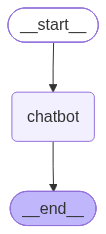

In [25]:
# ============================================================================
# PART 4: Show Chatbot Graph
# ============================================================================

display(Image(graph.get_graph().draw_mermaid_png()))

In [29]:
# ============================================================================
# PART 5: Invoking Chatbot Graph
# ============================================================================


response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="How much can I get reimbursed for internet?"
            )
        ]
    }
)

print(f"✓ Invoked Chatbot Graph")



PART 5: Invoking Chatbot Graph
✓ current_input_content --> How much can I get reimbursed for internet?
✓ chat_history --> []


> Entering new AgentExecutor chain...

Invoking: `company_policy_search` with `{'query': 'internet reimbursement policy'}`


ACME Corp Remote Work Policy (2026):
1. Employees may work remotely up to 3 days per week with manager approval.
2. A annual stipend of $500 is provided for home office equipment setup.
3. Core working hours are 10:00 AM to 4:00 PM EST.
4. Internet reimbursement covers up to $70/month with valid receipts.You can get reimbursed for internet expenses up to $70 per month, provided you submit valid receipts.

> Finished chain.
✓ Invoked Chatbot Graph


In [30]:
# ============================================================================
# PART 6: Display the Agent's Response
# ============================================================================


for message in response["messages"]:
    print(message.content)

print("\n" + "="*80)



How much can I get reimbursed for internet?
You can get reimbursed for internet expenses up to $70 per month, provided you submit valid receipts.

